In [1]:
from structured_optics import *
from structured_optics.hologram import slm_hologram
import numpy as np
import matplotlib.pyplot as plt

In [2]:
pixel_size = 8e-6
beam = Beam(nix = pixel_size*640/2, Dx = 640,
            niy = pixel_size*480/2, Dy = 480,
            waist = 0.5e-3, lamb = 633e-9)

In [62]:
#For fixed std

hg_modes = [[0,0], [0,1], [1,0], [2,0], [1,1], [0,2], [3,0], [2,1], [1,2], [0,3], [4,0], [3,1], [2,2], [1,3], [0,4], [5,0], [4,1], [3,2], [2,3], [1,4], [0,5]]
lg_modes = [[0,0], [0,1], [0,-1], [0,2], [1,0], [0,-2], [0,3], [1,1], [1,-1], [0,-3], [0,4], [1, 2], [1,-2], [2, 0], [0,-4], [0,5], [1,3], [1, -3], [2, 1], [2,-1], [0,-5]]

C = 0.6e-3
z = 30e-2


In [63]:
std_lg = []
for mode in range(len(lg_modes)):

    n = lg_modes[mode][0]   
    m = lg_modes[mode][1]

    beam.waist = np.sqrt(2*C**2/(2*n + np.abs(m) +1) + 2*np.sqrt(np.abs(C**4/(2*n + np.abs(m) +1)**2 - z**2/beam.k()**2)))
    print(beam.waist)
    beam.lg(l=m, p=n)
    beam.propagate(z)
    std_lg.append(beam.std()[0])
    """plt.figure()
    plt.pcolormesh(beam.x, beam.y, beam.int_profile())
    plt.title(f"l={m}, p={n}")"""


0.0011989404156813911
0.0008455110481668822
0.0008455110481668822
0.0006872140239591437
0.0006872140239591437
0.0006872140239591437
0.0005912249227889701
0.0005912249227889701
0.0005912249227889701
0.0005912249227889701
0.0005241170826979273
0.0005241170826979273
0.0005241170826979273
0.0005241170826979273
0.0005241170826979273
0.00047293092548301367
0.00047293092548301367
0.00047293092548301367
0.00047293092548301367
0.00047293092548301367
0.00047293092548301367


(0.0, 0.001)

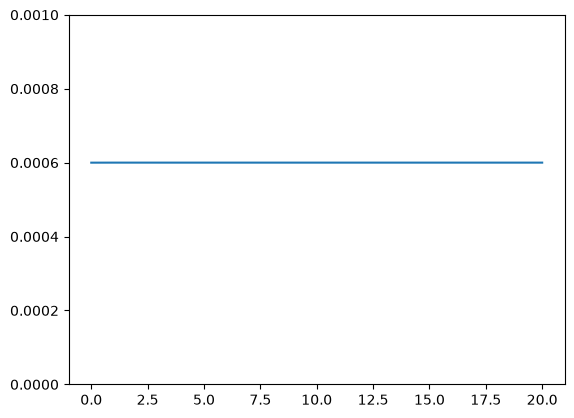

In [67]:
plt.plot(np.array(std_lg))
plt.ylim(0,1e-3)

In [68]:
std_hg = []

for n in range(5):
    
    beam.waist = np.sqrt(2*C**2/(2*n+1) + 2*np.sqrt(C**4/(2*n+1)**2 - z**2/beam.k()**2))
    print(beam.waist)
    beam.hg(n=n, m=0)
    beam.propagate(z)

    std_hg.append(beam.std()[0])
    """plt.figure()
    plt.pcolormesh(beam.x, beam.y, beam.int_profile())"""


0.0011989404156813911
0.0006872140239591437
0.0005241170826979273
0.00043136783804311265
0.000363873279889938


(0.0, 0.001)

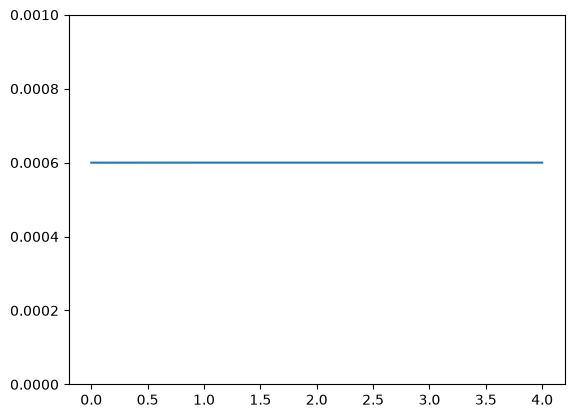

In [69]:
plt.plot(np.array(std_hg))
plt.ylim(0, 1e-3)